Weights: [10, 20, 30]
Values: [60, 100, 120]
Capacity: 50
Maximum Value: 240.0

Items	Average Time (seconds)	Peak Memory (KB)
10	0.00000507			0.508
20	0.00000638			0.570
30	0.00000959			0.633
40	0.00001241			0.695
50	0.00001530			0.789
60	0.00001962			0.883
70	0.00002206			0.977
80	0.00002302			1.102
90	0.00002576			1.102
100	0.00002714			1.250
110	0.00003222			1.641
120	0.00003399			1.875
130	0.00003774			3.281
140	0.00004193			3.594
150	0.00004349			4.094
160	0.00004512			4.406
170	0.00004876			4.719
180	0.00005313			5.250
190	0.00005433			5.562
200	0.00005579			5.875
210	0.00005969			6.438
220	0.00008259			6.750
230	0.00006502			7.062
240	0.00007232			7.656
250	0.00007225			7.969
260	0.00009412			8.281
270	0.00010632			10.984
280	0.00010156			11.375
290	0.00010947			11.719
300	0.00010455			12.125


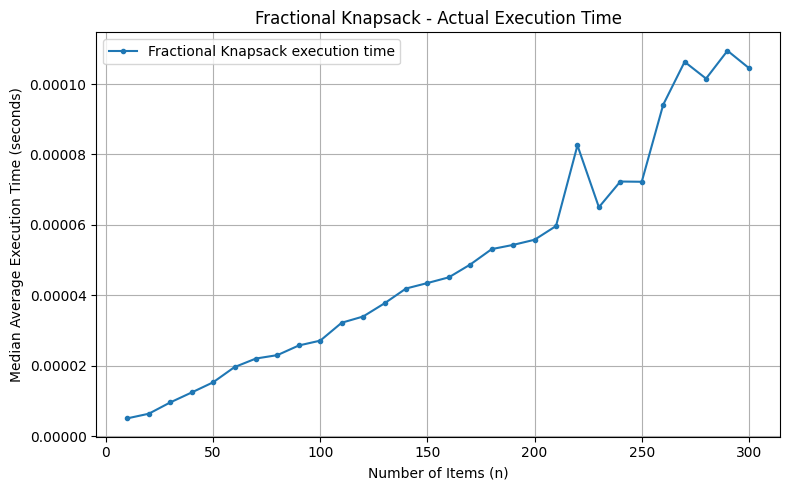

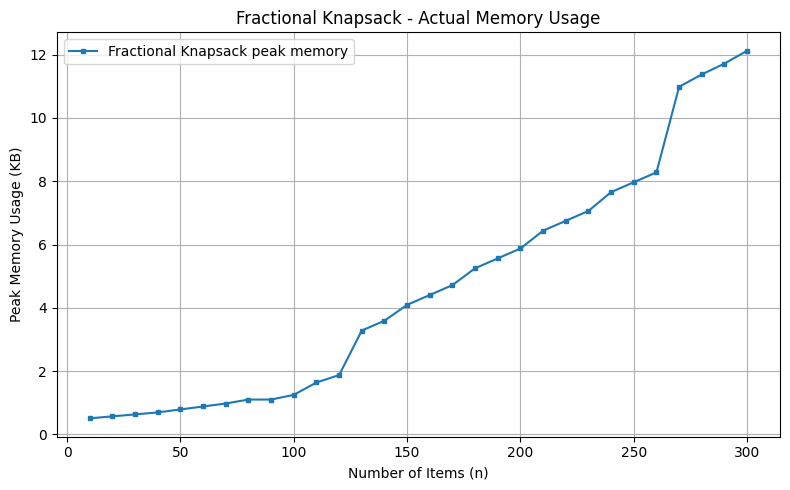

In [ ]:
import matplotlib.pyplot as plt
from time import perf_counter
import tracemalloc
import statistics


def fractional_knapsack(weights, values, capacity):
    items = sorted(
        zip(weights, values),
        key=lambda item: item[1] / item[0],
        reverse=True
    )

    total_value = 0
    for weight, value in items:
        if capacity <= 0:
            break

        take = min(weight, capacity)
        total_value += take * value / weight
        capacity -= take

    return total_value


def measure_time(function, *args, repeats=5, runs_per_repeat=20):
    """Median of average execution times, in seconds."""
    averages = []
    for _ in range(repeats):
        start = perf_counter()
        for _ in range(runs_per_repeat):
            function(*args)
        averages.append((perf_counter() - start) / runs_per_repeat)
    return statistics.median(averages)


def measure_memory(function, *args, repeats=3):
    """Median peak Python-tracked allocation, in KB."""
    peaks = []
    for _ in range(repeats):
        tracemalloc.start()
        try:
            function(*args)
            _, peak = tracemalloc.get_traced_memory()
        finally:
            tracemalloc.stop()
        peaks.append(peak / 1024)
    return statistics.median(peaks)


# Example input
weights = [10, 20, 30]
values = [60, 100, 120]
capacity = 50
print("Weights:", weights)
print("Values:", values)
print("Capacity:", capacity)
print("Maximum Value:", fractional_knapsack(weights, values, capacity))

# Generate input data outside the timed/memory-measured function.
all_weights = [(i % 20) + 1 for i in range(1, 301)]
all_values = [((i * 7) % 100) + 10 for i in range(1, 301)]
sizes = list(range(10, 301, 10))
execution_times = []
peak_memory = []

for n in sizes:
    test_weights = all_weights[:n]
    test_values = all_values[:n]
    test_capacity = sum(test_weights) // 2

    execution_times.append(
        measure_time(fractional_knapsack, test_weights, test_values, test_capacity)
    )
    peak_memory.append(
        measure_memory(fractional_knapsack, test_weights, test_values, test_capacity)
    )

print("\nItems\tAverage Time (seconds)\tPeak Memory (KB)")
for n, t, m in zip(sizes, execution_times, peak_memory):
    print(f"{n}\t{t:.8f}\t\t\t{m:.3f}")

# Graph 1: Actual execution time
plt.figure(figsize=(8, 5))
plt.plot(sizes, execution_times, marker='o', markersize=3,
         label="Fractional Knapsack execution time")
plt.xlabel("Number of Items (n)")
plt.ylabel("Median Average Execution Time (seconds)")
plt.title("Fractional Knapsack - Actual Execution Time")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Graph 2: Actual peak memory usage
plt.figure(figsize=(8, 5))
plt.plot(sizes, peak_memory, marker='s', markersize=3,
         label="Fractional Knapsack peak memory")
plt.xlabel("Number of Items (n)")
plt.ylabel("Peak Memory Usage (KB)")
plt.title("Fractional Knapsack - Actual Memory Usage")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
